In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Bank Marketing — Exploratory Data Analysis

## Project Overview

This project aims to predict whether a customer will
subscribe to a bank term deposit based on demographic,
financial, and campaign-related features.

The objective of this notebook is to explore the dataset,
identify potential data quality issues, and investigate
relationships between features and the target variable.

In [2]:
df = pd.read_csv(
    "../data/raw/bank-full.csv",
    sep=";",
)

In [4]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [5]:
df.shape

(45211, 17)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


In [7]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [8]:
df.isnull().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

In [9]:
df["job"].value_counts()

job
blue-collar      9732
management       9458
technician       7597
admin.           5171
services         4154
retired          2264
self-employed    1579
entrepreneur     1487
unemployed       1303
housemaid        1240
student           938
unknown           288
Name: count, dtype: int64

In [31]:
df["pdays"].value_counts().head(10)

pdays
-1      36954
 182      167
 92       147
 91       126
 183      126
 181      117
 370       99
 184       85
 364       77
 95        74
Name: count, dtype: int64

In [11]:
df["y"].value_counts()

y
no     39922
yes     5289
Name: count, dtype: int64

In [12]:
df["y"].value_counts(normalize=True)

y
no     0.883015
yes    0.116985
Name: proportion, dtype: float64

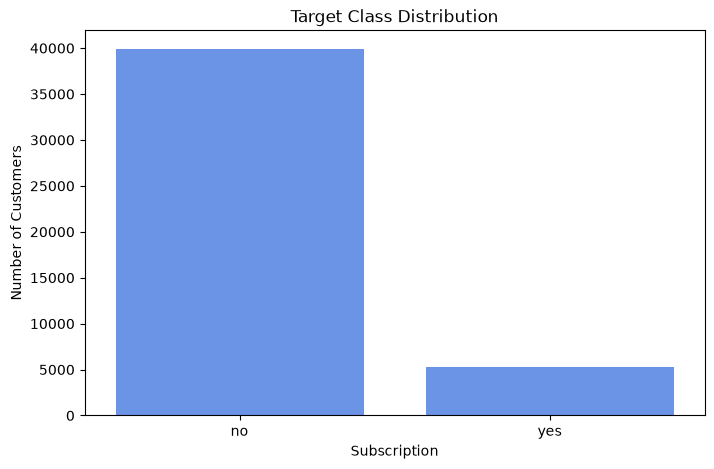

In [13]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="y"
)

plt.title("Target Class Distribution")
plt.xlabel("Subscription")
plt.ylabel("Number of Customers")

plt.show()

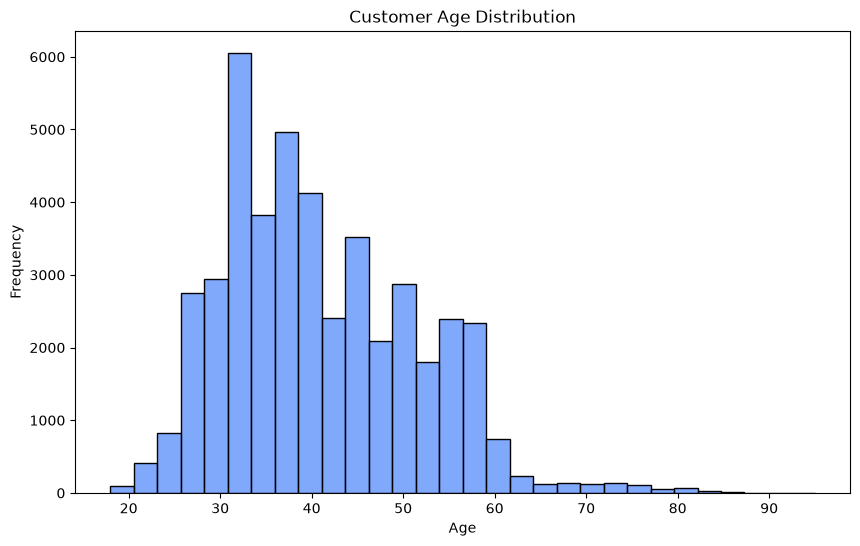

In [14]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="age",
    bins=30
)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

In [32]:
duplicate_rows = df.duplicated().sum()
duplicate_rows

np.int64(0)

In [17]:
categorical_columns = df.select_dtypes(
    include=["object", "string"]
).columns

unknown_summary = pd.DataFrame({
    "unknown_count": (df[categorical_columns] == "unknown").sum(),
    "unknown_percentage": (
        (df[categorical_columns] == "unknown").mean() * 100
    ).round(2)
}).sort_values("unknown_count", ascending=False)

unknown_summary

,unknown_count,unknown_percentage
poutcome,36959,81.75
contact,13020,28.80
education,1857,4.11
job,288,0.64
marital,0,0.00
default,0,0.00
housing,0,0.00
loan,0,0.00
month,0,0.00
y,0,0.00


## Initial Findings

### Observations supported by the notebook outputs

- The dataset contains 45,211 observations and 17 columns. Seven columns are integer-valued and ten are stored as strings.
- No duplicate rows were detected in the dataset.
- Although Pandas detected no null or `NaN` values, several categorical columns contain `unknown`. This value occurs 36,959 times in `poutcome` (81.75%), 13,020 times in `contact` (28.80%), 1,857 times in `education` (4.11%), and 288 times in `job` (0.64%). These values may represent unavailable information, but their meaning should be verified before deciding how to handle them.
- The target variable is highly imbalanced: 39,922 observations (88.30%) belong to the `no` class, while 5,289 observations (11.70%) belong to the `yes` class. Therefore, accuracy alone will not be sufficient for evaluating future models.
- Customer age ranges from 18 to 95 years, with a median of 39 years. The middle 50% of customers are between 33 and 48 years old. The histogram shows a concentration of observations among working-age customers and a sparse right tail at older ages.
- Some numerical variables have maxima far above their third quartiles. For example, `balance` has a median of 448 and a maximum of 102,127, while `duration` has a median of 180 and a maximum of 4,918.
- The value `-1` occurs 36,954 times in `pdays`, representing approximately 81.74% of the dataset. In addition, at least 75% of the observations have `previous`    equal to 0.

### Hypotheses and questions for further analysis

- The large ranges observed in `balance`, `duration`, `campaign`, and `previous` may indicate right-skewed distributions or influential extreme observations. Additional plots are required before deciding whether any treatment is necessary.
- The value `unknown` may represent missing or unavailable information, but this should be verified using the dataset documentation before recoding it.
- The meaning of `pdays = -1` should also be confirmed before treating it as an ordinary numerical value.

## Feature Relationships with the Target

In [23]:
numeric_features = [
    "age",
    "balance",
    "duration",
    "campaign",
    "pdays",
    "previous",
]

df.groupby("y")[numeric_features].agg(
    ["mean", "median"]
).T

y                         no          yes
age      mean      40.838986    41.670070
         median    39.000000    38.000000
balance  mean    1303.714969  1804.267915
         median   417.000000   733.000000
duration mean     221.182806   537.294574
         median   164.000000   426.000000
campaign mean       2.846350     2.141047
         median     2.000000     2.000000
pdays    mean      36.421372    68.702968
         median    -1.000000    -1.000000
previous mean       0.502154     1.170354
         median     0.000000     0.000000

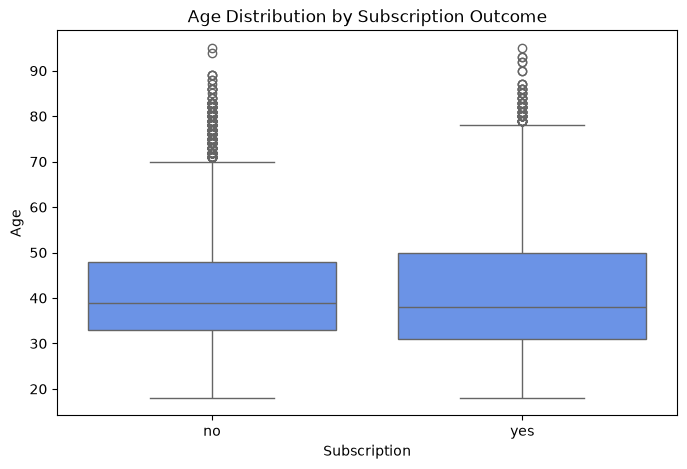

In [24]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="y",
    y="age",
)

plt.title("Age Distribution by Subscription Outcome")
plt.xlabel("Subscription")
plt.ylabel("Age")

plt.show()

In [33]:
def subscription_rate_by_category(column):
    summary = (
        df.groupby(column)["y"]
        .agg(
            total_customers="size",
            subscriptions=lambda values: (values == "yes").sum(),
        )
    )

    summary["subscription_rate_percent"] = (
        summary["subscriptions"]
        / summary["total_customers"]
        * 100
    ).round(2)

    return summary.sort_values(
        "subscription_rate_percent",
        ascending=False,
    )

In [34]:
subscription_rate_by_category("job")

,total_customers,subscriptions,subscription_rate_percent
job,,,
student,938,269,28.68
retired,2264,516,22.79
unemployed,1303,202,15.50
management,9458,1301,13.76
admin.,5171,631,12.20
self-employed,1579,187,11.84
unknown,288,34,11.81
technician,7597,840,11.06
services,4154,369,8.88


In [35]:
subscription_rate_by_category("education")

,total_customers,subscriptions,subscription_rate_percent
education,,,
tertiary,13301,1996,15.01
unknown,1857,252,13.57
secondary,23202,2450,10.56
primary,6851,591,8.63


In [36]:
subscription_rate_by_category("housing")

,total_customers,subscriptions,subscription_rate_percent
housing,,,
no,20081,3354,16.7
yes,25130,1935,7.7


In [37]:
subscription_rate_by_category("loan")

,total_customers,subscriptions,subscription_rate_percent
loan,,,
no,37967,4805,12.66
yes,7244,484,6.68


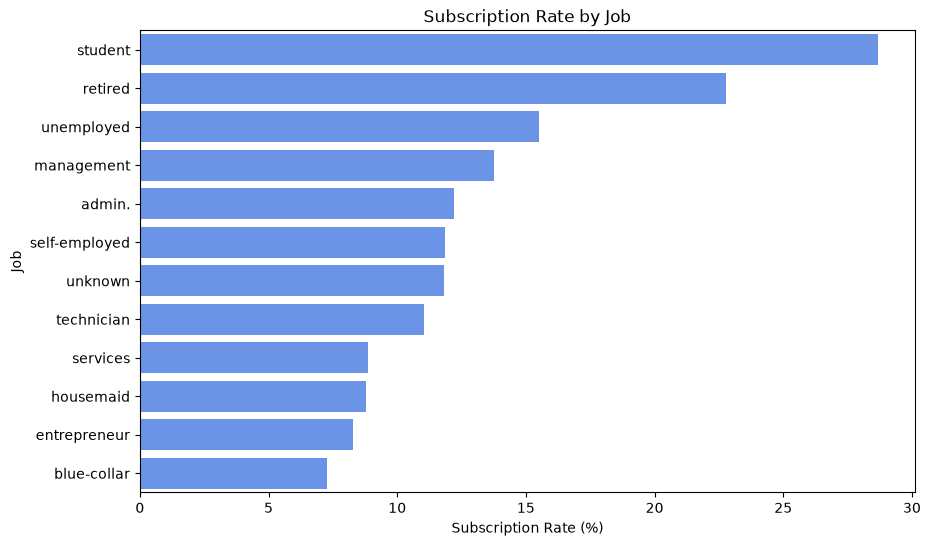

In [38]:
job_subscription_rate = (
    subscription_rate_by_category("job")
    .reset_index()
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=job_subscription_rate,
    x="subscription_rate_percent",
    y="job",
)

plt.title("Subscription Rate by Job")
plt.xlabel("Subscription Rate (%)")
plt.ylabel("Job")

plt.show()

### Feature Relationship Findings

#### Observed associations

- The age distributions of subscribers and non-subscribers overlap considerably. Their median ages are similar: 38 years for subscribers and 39 years for non-subscribers. Age alone does not appear to provide a clear separation between the two classes.
- Subscribers have a higher median balance than non-subscribers: 733 compared with 417.
- Call duration shows the largest observed difference. Its median is 426 seconds for subscribers and 164 seconds for non-subscribers. However, duration is only known after the call and may cause data leakage if the model is intended to make predictions before contact.
- The median number of campaign contacts is 2 for both target classes, although the mean is lower for subscribers.
- The medians of `pdays` and `previous` are identical for both classes. Their means should be interpreted cautiously because these variables contain many repeated special or zero values.
- Subscription rates vary across job categories. Students have the highest observed rate at 28.68%, followed by retired customers at 22.79%. Blue-collar customers have the lowest observed rate at 7.27%.
- Customers with tertiary education have a higher observed subscription rate than customers with primary education: 15.01% compared with 8.63%.
- Customers without a housing loan have an observed subscription rate of 16.70%, compared with 7.70% for customers with a housing loan.
- Customers without a personal loan have an observed subscription rate of 12.66%, compared with 6.68% for customers with a personal loan.

#### Interpretation limits

- These results describe unadjusted associations and do not demonstrate that any feature causes a customer to subscribe.
- Category sizes differ, so percentages should be considered together with the number of observations in each category.
- Relationships may change after controlling for other variables during model development.

In [39]:
subscription_rate_by_category("marital")

,total_customers,subscriptions,subscription_rate_percent
marital,,,
single,12790,1912,14.95
divorced,5207,622,11.95
married,27214,2755,10.12


In [40]:
subscription_rate_by_category("default")

,total_customers,subscriptions,subscription_rate_percent
default,,,
no,44396,5237,11.80
yes,815,52,6.38


In [46]:
subscription_rate_by_category("contact")

,total_customers,subscriptions,subscription_rate_percent
contact,,,
cellular,29285,4369,14.92
telephone,2906,390,13.42
unknown,13020,530,4.07


In [44]:
subscription_rate_by_category("month")

,total_customers,subscriptions,subscription_rate_percent
month,,,
mar,477,248,51.99
dec,214,100,46.73
sep,579,269,46.46
oct,738,323,43.77
apr,2932,577,19.68
feb,2649,441,16.65
aug,6247,688,11.01
jun,5341,546,10.22
nov,3970,403,10.15


In [45]:
subscription_rate_by_category("poutcome")

,total_customers,subscriptions,subscription_rate_percent
poutcome,,,
success,1511,978,64.73
other,1840,307,16.68
failure,4901,618,12.61
unknown,36959,3386,9.16


## EDA Conclusions

### Data quality

- The dataset contains 45,211 observations and 17 columns, with no duplicate rows and no explicit null or `NaN` values.
- Missing or unavailable information may instead be represented by the category `unknown`. This value is particularly frequent in `poutcome` (81.75%) and `contact` (28.80%), while it is less frequent in `education` (4.11%) and `job` (0.64%).
- The value `-1` occurs 36,954 times in `pdays`, representing approximately 81.74% of the dataset. Its meaning must be confirmed before deciding how to encode or transform this variable.
- Several numerical variables, including `balance`, `duration`, `campaign`, and `previous`, have wide ranges and maxima far above their third quartiles. These values should not be removed automatically without further investigation.

### Target distribution

- The target variable is strongly imbalanced: 39,922 observations (88.30%) belong to the `no` class and 5,289 observations (11.70%) belong to the `yes` class.
- A model predicting only the majority class would already obtain an accuracy of 88.30%. Therefore, future evaluation should also consider precision, recall, F1-score, ROC-AUC, and metrics focused on the minority class.

### Observed feature relationships

- The age distributions of subscribers and non-subscribers overlap substantially. Their median ages are similar, suggesting that age alone does not clearly separate the two classes.
- Subscribers have a higher median balance than non-subscribers: 733 compared with 417.
- Call duration shows the largest numerical difference between the target classes, with a median of 426 seconds for subscribers and 164 seconds for non-subscribers. However, this variable is only known after the call and should be excluded if the model is intended to make predictions before customer contact.
- Students and retired customers have the highest observed subscription rates among job categories, at 28.68% and 22.79%, respectively. Blue-collar customers have the lowest observed rate, at 7.27%.
- Customers with tertiary education have a higher observed subscription rate than customers with primary education: 15.01% compared with 8.63%.
- Customers without housing or personal loans show higher observed subscription rates than customers with those loans.
- Single customers have an observed subscription rate of 14.95%, compared with 11.95% for divorced customers and 10.12% for married customers.
- Customers without credit default have an observed subscription rate of 11.80%, compared with 6.38% for customers with default. However, the default group contains only 815 observations.
- Cellular and telephone contacts have observed subscription rates of 14.92% and 13.42%, respectively, compared with 4.07% for records where the contact method is `unknown`.
- March, December, September, and October have the highest observed monthly subscription rates. These months contain fewer observations than months such as May, so their percentages should be interpreted together with their sample sizes.
- A previous campaign outcome of `success` is associated with the highest observed subscription rate, at 64.73%. However, this category contains 1,511 observations, while `poutcome` is `unknown` for 36,959 observations.

### Interpretation limits and next steps

- The relationships found in this notebook are descriptive and do not demonstrate causality.
- The analyses consider each feature separately. Some observed differences may be explained by interactions or confounding relationships with other variables.
- The `unknown` categories and the special value `pdays = -1` should be handled explicitly during preprocessing rather than treated automatically as ordinary missing values.
- Categorical variables will require encoding, while numerical transformations should be evaluated according to the requirements of each model.
- The train-test split should preserve the target-class distribution, and all learned preprocessing operations must be fitted only on the training data.
- The next phase will define a reproducible preprocessing pipeline and prepare the data for the first baseline classification model.